In [1]:
import pandas as pd

In [2]:
model_1 = pd.read_csv("submission_v1.csv")
model_2 = pd.read_csv("submission_v2.csv")

In [3]:
model_1.head()

,id,addicted_label
0,691369,0.999464
1,691370,0.963851
2,691371,0.950807
3,691372,0.991816
4,691373,0.997496


In [4]:
model_2.head()

,id,addicted_label
0,691369,0.999036
1,691370,0.995065
2,691371,0.913952
3,691372,0.981572
4,691373,0.995205


In [5]:
ensemble = pd.DataFrame()

In [6]:
ensemble["id"]=model_1["id"]

In [7]:
ensemble["addicted_label"] = -0.1*model_1["addicted_label"]+1.1*model_2["addicted_label"]

In [8]:
ensemble.to_csv("submission_ensemble_2.csv",index=False)

In [10]:
ensemble["addicted_label"] = 0.5*model_1["addicted_label"]+0.5*model_2["addicted_label"]
ensemble.to_csv("submission_ensemble_1.csv",index=False)

In [11]:
ensemble["addicted_label"] = -1*model_1["addicted_label"]+2*model_2["addicted_label"]
ensemble.to_csv("submission_ensemble_3.csv",index=False)

In [12]:
# correlation plot

In [13]:
all_model = model_1

In [14]:
all_model['addicted_label_2'] = model_2['addicted_label']

In [16]:
all_model.head()

,id,addicted_label,addicted_label_2
0,691369,0.999464,0.999036
1,691370,0.963851,0.995065
2,691371,0.950807,0.913952
3,691372,0.991816,0.981572
4,691373,0.997496,0.995205


In [17]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr

In [19]:
# Calculate Pearson correlation coefficient
corr, _ = pearsonr(all_model['addicted_label'], all_model['addicted_label_2'])


In [25]:
corr

np.float64(0.9641529832014233)

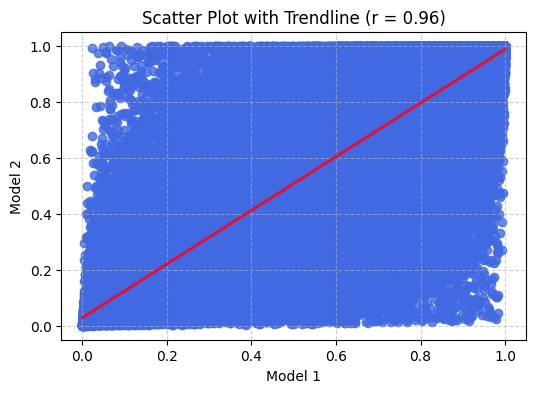

In [24]:
# Create the plot
plt.figure(figsize=(6, 4))
sns.regplot(x=all_model['addicted_label'], y=all_model['addicted_label_2'], color="royalblue", line_kws={"color": "crimson"})

# Style the plot
plt.title(f"Scatter Plot with Trendline (r = {corr:.2f})")
plt.xlabel("Model 1")
plt.ylabel("Model 2")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

<Axes: >

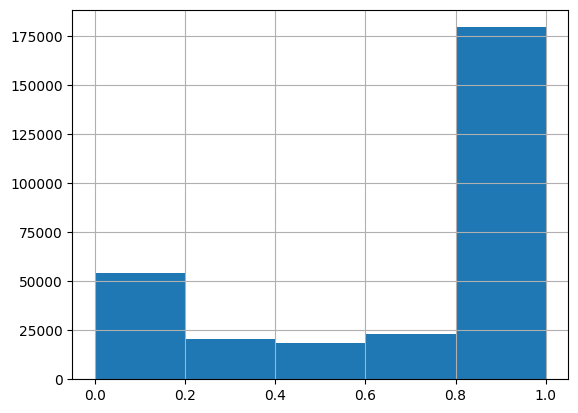

In [28]:
model_1["addicted_label"].hist(bins=5)

<Axes: >

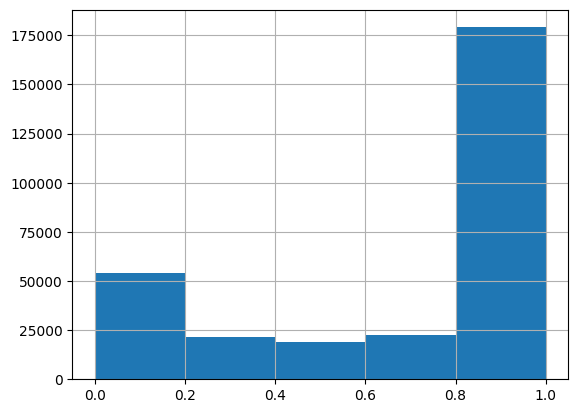

In [29]:
model_2["addicted_label"].hist(bins=5)

In [26]:
# it is clearly that the correlation should be low. or at least the deviation should be high. tapi kalau di cek nilai korelasinya ko tinggi

In [27]:
all_model

,id,addicted_label,addicted_label_2
0,691369,0.999464,0.999036
1,691370,0.963851,0.995065
2,691371,0.950807,0.913952
3,691372,0.991816,0.981572
4,691373,0.997496,0.995205
...,...,...,...
296297,987666,1.000000,0.999998
296298,987667,0.927203,0.922501
296299,987668,0.204447,0.195129
296300,987669,0.711592,0.585426


In [34]:
def model_prob(row):
    if row['addicted_label']>row['addicted_label_2'] and row['addicted_label']>=0.5:
        return row['addicted_label']
    elif row['addicted_label']>row['addicted_label_2'] and row['addicted_label']<0.5:
        return row['addicted_label_2']
    elif row['addicted_label_2']>row['addicted_label'] and row['addicted_label_2']>=0.5:
        return row['addicted_label_2']
    else:
        return row['addicted_label']

In [35]:
all_model['composite_addicted'] = all_model.apply(model_prob,axis=1)

In [36]:
all_model

,id,addicted_label,addicted_label_2,composite_addicted
0,691369,0.999464,0.999036,0.999464
1,691370,0.963851,0.995065,0.995065
2,691371,0.950807,0.913952,0.950807
3,691372,0.991816,0.981572,0.991816
4,691373,0.997496,0.995205,0.997496
...,...,...,...,...
296297,987666,1.000000,0.999998,1.000000
296298,987667,0.927203,0.922501,0.927203
296299,987668,0.204447,0.195129,0.195129
296300,987669,0.711592,0.585426,0.711592


In [39]:
submission_4 = pd.DataFrame()

In [40]:
submission_4['id'] = all_model['id']
submission_4['addicted_label']=all_model['composite_addicted']

In [42]:
submission_4

,id,addicted_label
0,691369,0.999464
1,691370,0.995065
2,691371,0.950807
3,691372,0.991816
4,691373,0.997496
...,...,...
296297,987666,1.000000
296298,987667,0.927203
296299,987668,0.195129
296300,987669,0.711592


In [43]:
submission_4.to_csv("submission_ensemble_4.csv",index=False)

<Axes: >

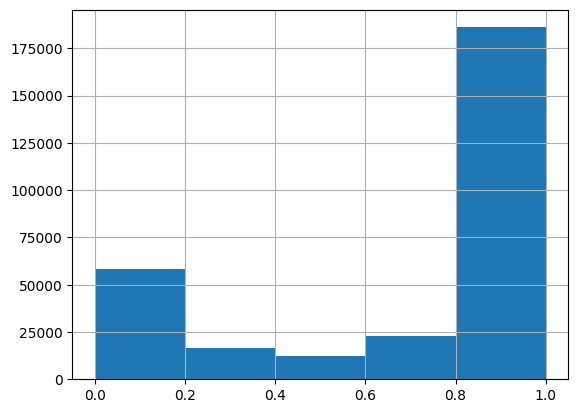

In [44]:
all_model["composite_addicted"].hist(bins=5)